In [1]:
from __future__ import annotations

import operator
import time
from pathlib import Path
from typing import TypedDict, List, Optional, Literal, Annotated

from pydantic import BaseModel, Field, field_validator, model_validator

from langgraph.graph import StateGraph, START, END
from langgraph.types import Send

from langchain_ollama import ChatOllama, OllamaEmbeddings
from langchain_core.messages import SystemMessage, HumanMessage
from ollama import ResponseError
from langchain_tavily import TavilySearch
from dotenv import load_dotenv

load_dotenv()

True

In [2]:
# -----------------------------
# 1) Schemas
# -----------------------------
class Task(BaseModel):
    id: int = Field(default=0, description="Section number as an integer, starting at 1")
    title: str = Field(..., description="Short section heading")

    # gpt-oss often renames fields (e.g. target_word_count) or drops title.
    # Map known aliases and fill safe defaults so one sloppy section doesn't fail the plan.
    @model_validator(mode="before")
    @classmethod
    def _normalize_keys(cls, data):
        if not isinstance(data, dict):
            return data
        d = dict(data)
        if "target_words" not in d:
            for k in ("target_word_count", "word_count", "words", "target_length", "length"):
                if k in d:
                    d["target_words"] = d[k]
                    break
        try:
            d["target_words"] = int(d.get("target_words", 300))
        except (TypeError, ValueError):
            d["target_words"] = 300
        if not d.get("title"):
            for k in ("section_title", "heading", "header", "name", "section", "topic", "subject"):
                if isinstance(d.get(k), str) and d[k].strip():
                    d["title"] = d[k].strip()
                    break
            else:
                goal = str(d.get("goal") or "").strip()
                d["title"] = goal.split(".")[0][:60] or "Section"
        return d

    # gpt-oss sometimes puts a slug like 'intro' in id; ids are renumbered in orchestrator_node.
    @field_validator("id", mode="before")
    @classmethod
    def _coerce_id(cls, v):
        try:
            return int(v)
        except (TypeError, ValueError):
            return 0

    goal: str = Field(
        ...,
        description="One sentence describing what the reader should be able to do/understand after this section.",
    )
    bullets: List[str] = Field(
        ...,
        min_length=3,
        max_length=6,
        description="3–6 concrete, non-overlapping subpoints to cover in this section.",
    )
    target_words: int = Field(..., description="Target word count for this section (120–550).")

    tags: List[str] = Field(default_factory=list)
    requires_research: bool = False
    requires_citations: bool = False
    requires_code: bool = False


class Plan(BaseModel):
    blog_title: str
    audience: str
    tone: str
    blog_kind: Literal["explainer", "tutorial", "news_roundup", "comparison", "system_design"] = "explainer"
    constraints: List[str] = Field(default_factory=list)
    tasks: List[Task]


class EvidenceItem(BaseModel):
    title: str
    url: str
    published_at: Optional[str] = None  # keep if Tavily provides; DO NOT rely on it
    snippet: Optional[str] = None
    source: Optional[str] = None


class RouterDecision(BaseModel):
    needs_research: bool
    mode: Literal["closed_book", "hybrid", "open_book"]
    queries: List[str] = Field(default_factory=list)


class EvidencePack(BaseModel):
    evidence: List[EvidenceItem] = Field(default_factory=list)


In [3]:
class State(TypedDict):
    topic: str

    # routing / research
    mode: str
    needs_research: bool
    queries: List[str]
    evidence: List[EvidenceItem]
    plan: Optional[Plan]

    # workers
    sections: Annotated[List[tuple[int, str]], operator.add]  # (task_id, section_md)
    final: str

In [4]:
llm = ChatOllama( model="gpt-oss:120b-cloud",temperature=0.3,)
embeddings = OllamaEmbeddings(model="nomic-embed-text:latest")

In [5]:
# -----------------------------
# 3) Router (decide upfront)
# -----------------------------
ROUTER_SYSTEM = """You are a routing module for a technical blog planner.

Decide whether web research is needed BEFORE planning.

Modes:
- closed_book (needs_research=false):
  Evergreen topics where correctness does not depend on recent facts (concepts, fundamentals).
- hybrid (needs_research=true):
  Mostly evergreen but needs up-to-date examples/tools/models to be useful.
- open_book (needs_research=true):
  Mostly volatile: weekly roundups, "this week", "latest", rankings, pricing, policy/regulation.

If needs_research=true:
- Output 3–10 high-signal queries.
- Queries should be scoped and specific (avoid generic queries like just "AI" or "LLM").
- If user asked for "last week/this week/latest", reflect that constraint IN THE QUERIES.
"""

def router_node(state: State) -> dict:
    
    topic = state["topic"]
    decider = llm.with_structured_output(RouterDecision, method="function_calling")
    decision = decider.invoke(
        [
            SystemMessage(content=ROUTER_SYSTEM),
            HumanMessage(content=f"Topic: {topic}"),
        ]
    )

    if decision is None:  # model made no tool call: skip research
        decision = RouterDecision(needs_research=False, mode="closed_book", queries=[])

    return {
        "needs_research": decision.needs_research,
        "mode": decision.mode,
        "queries": decision.queries,
    }

def route_next(state: State) -> str:
    return "research" if state["needs_research"] else "orchestrator"

In [6]:
# -----------------------------
# 4) Research (Tavily) 
# -----------------------------
def _tavily_search(query: str, max_results: int = 5) -> List[dict]:
    
    tool = TavilySearch(max_results=max_results)
    response = tool.invoke({"query": query})

    # TavilySearch returns {"query": ..., "results": [...]}; tolerate a plain list too
    results = response.get("results", []) if isinstance(response, dict) else response

    normalized: List[dict] = []
    for r in results or []:
        normalized.append(
            {
                "title": r.get("title") or "",
                "url": r.get("url") or "",
                "snippet": r.get("content") or r.get("snippet") or "",
                "published_at": r.get("published_date") or r.get("published_at"),
                "source": r.get("source"),
            }
        )
    return normalized


RESEARCH_SYSTEM = """You are a research synthesizer for technical writing.

Given raw web search results, produce a deduplicated list of EvidenceItem objects.

Rules:
- Only include items with a non-empty url.
- Prefer relevant + authoritative sources (company blogs, docs, reputable outlets).
- If a published date is explicitly present in the result payload, keep it as YYYY-MM-DD.
  If missing or unclear, set published_at=null. Do NOT guess.
- Keep snippets short.
- Deduplicate by URL.
"""

def research_node(state: State) -> dict:

    # take the first 10 queries from state
    queries = (state.get("queries", []) or [])
    max_results = 6

    raw_results: List[dict] = []

    for q in queries:
        raw_results.extend(_tavily_search(q, max_results=max_results))

    if not raw_results:
        return {"evidence": []}

    # Build evidence directly from Tavily results (the LLM extractor sometimes
    # returned None under function_calling). Drop empty URLs, dedupe by URL.
    dedup = {}
    for r in raw_results:
        url = (r.get("url") or "").strip()
        if not url or url in dedup:
            continue
        dedup[url] = EvidenceItem(
            title=r.get("title") or url,
            url=url,
            published_at=r.get("published_at"),
            snippet=(r.get("snippet") or "")[:300],
            source=r.get("source"),
        )

    return {"evidence": list(dedup.values())}

In [7]:
# -----------------------------
# 5) Orchestrator (Plan)
# -----------------------------
ORCH_SYSTEM = """You are a senior technical writer and developer advocate.
Your job is to produce a highly actionable outline for a technical blog post.

Hard requirements:
- Create 5–9 sections (tasks) suitable for the topic and audience.
- Each task must include:
  1) goal (1 sentence)
  2) 3–6 bullets that are concrete, specific, and non-overlapping
  3) target word count (120–550)

Quality bar:
- Assume the reader is a developer; use correct terminology.
- Bullets must be actionable: build/compare/measure/verify/debug.
- Ensure the overall plan includes at least 2 of these somewhere:
  * minimal code sketch / MWE (set requires_code=True for that section)
  * edge cases / failure modes
  * performance/cost considerations
  * security/privacy considerations (if relevant)
  * debugging/observability tips

Grounding rules:
- Mode closed_book: keep it evergreen; do not depend on evidence.
- Mode hybrid:
  - Use evidence for up-to-date examples (models/tools/releases) in bullets.
  - Mark sections using fresh info as requires_research=True and requires_citations=True.
- Mode open_book:
  - Set blog_kind = "news_roundup".
  - Every section is about summarizing events + implications.
  - DO NOT include tutorial/how-to sections unless user explicitly asked for that.
  - If evidence is empty or insufficient, create a plan that transparently says "insufficient sources"
    and includes only what can be supported.

Field names are exact. Each task must use these keys and no others:
id (int), title (str), goal (str), bullets (list[str]), target_words (int),
tags (list[str]), requires_research (bool), requires_citations (bool), requires_code (bool).
Always include title and target_words.

Output must strictly match the Plan schema.
"""

def orchestrator_node(state: State) -> dict:
    planner = llm.with_structured_output(Plan, method="function_calling")

    evidence = state.get("evidence", [])
    mode = state.get("mode", "closed_book")

    messages = [
            SystemMessage(content=ORCH_SYSTEM),
            HumanMessage(
                content=(
                    f"Topic: {state['topic']}\n"
                    f"Mode: {mode}\n\n"
                    f"Evidence (ONLY use for fresh claims; may be empty):\n"
                    f"{[e.model_dump() for e in evidence][:16]}"
                )
            ),
        ]

    plan = None
    for _ in range(3):  # model occasionally makes no tool call and returns None
        plan = planner.invoke(messages)
        if plan is not None:
            break
    if plan is None:
        raise RuntimeError("Orchestrator: model returned no Plan after 3 attempts")

    # ids are not trusted from the model: renumber 1..N in order
    for i, task in enumerate(plan.tasks, start=1):
        task.id = i

    return {"plan": plan}

In [8]:
# -----------------------------
# 6) Fanout
# -----------------------------
def fanout(state: State):
    return [
        Send(
            "worker",
            {
                "task": task.model_dump(),
                "topic": state["topic"],
                "mode": state["mode"],
                "plan": state["plan"].model_dump(),
                "evidence": [e.model_dump() for e in state.get("evidence", [])],
            },
        )
        for task in state["plan"].tasks
    ]

In [9]:
# -----------------------------
# 7) Worker (write one section)
# -----------------------------
WORKER_SYSTEM = """You are a senior technical writer and developer advocate.
Write ONE section of a technical blog post in Markdown.

Hard constraints:
- Follow the provided Goal and cover ALL Bullets in order (do not skip or merge bullets).
- Stay close to Target words (±15%).
- Output ONLY the section content in Markdown (no blog title H1, no extra commentary).
- Start with a '## <Section Title>' heading.

Scope guard:
- If blog_kind == "news_roundup": do NOT turn this into a tutorial/how-to guide.
  Do NOT teach web scraping, RSS, automation, or "how to fetch news" unless bullets explicitly ask for it.
  Focus on summarizing events and implications.

Grounding policy:
- If mode == open_book:
  - Do NOT introduce any specific event/company/model/funding/policy claim unless it is supported by provided Evidence URLs.
  - For each event claim, attach a source as a Markdown link: ([Source](URL)).
  - Only use URLs provided in Evidence. If not supported, write: "Not found in provided sources."
- If requires_citations == true:
  - For outside-world claims, cite Evidence URLs the same way.
- Evergreen reasoning is OK without citations unless requires_citations is true.

Code:
- If requires_code == true, include at least one minimal, correct code snippet relevant to the bullets.

Style:
- Short paragraphs, bullets where helpful, code fences for code.
- Avoid fluff/marketing. Be precise and implementation-oriented.
"""

def _invoke_with_retry(messages, retries: int = 5, base_delay: float = 3.0):
    """Ollama cloud returns 429 when too many requests run at once; back off and retry."""
    for attempt in range(retries):
        try:
            return llm.invoke(messages)
        except ResponseError as e:
            if e.status_code != 429 or attempt == retries - 1:
                raise
            time.sleep(base_delay * (2 ** attempt))


def worker_node(payload: dict) -> dict:
    
    task = Task(**payload["task"])
    plan = Plan(**payload["plan"])
    evidence = [EvidenceItem(**e) for e in payload.get("evidence", [])]
    topic = payload["topic"]
    mode = payload.get("mode", "closed_book")

    bullets_text = "\n- " + "\n- ".join(task.bullets)

    evidence_text = ""
    if evidence:
        evidence_text = "\n".join(
            f"- {e.title} | {e.url} | {e.published_at or 'date:unknown'}".strip()
            for e in evidence[:20]
        )

    section_md = _invoke_with_retry(
        [
            SystemMessage(content=WORKER_SYSTEM),
            HumanMessage(
                content=(
                    f"Blog title: {plan.blog_title}\n"
                    f"Audience: {plan.audience}\n"
                    f"Tone: {plan.tone}\n"
                    f"Blog kind: {plan.blog_kind}\n"
                    f"Constraints: {plan.constraints}\n"
                    f"Topic: {topic}\n"
                    f"Mode: {mode}\n\n"
                    f"Section title: {task.title}\n"
                    f"Goal: {task.goal}\n"
                    f"Target words: {task.target_words}\n"
                    f"Tags: {task.tags}\n"
                    f"requires_research: {task.requires_research}\n"
                    f"requires_citations: {task.requires_citations}\n"
                    f"requires_code: {task.requires_code}\n"
                    f"Bullets:{bullets_text}\n\n"
                    f"Evidence (ONLY use these URLs when citing):\n{evidence_text}\n"
                )
            ),
        ]
    ).content.strip()

    return {"sections": [(task.id, section_md)]}

In [10]:
# -----------------------------
# 8) Reducer (merge + save)
# -----------------------------
def reducer_node(state: State) -> dict:

    plan = state["plan"]

    ordered_sections = [md for _, md in sorted(state["sections"], key=lambda x: x[0])]
    body = "\n\n".join(ordered_sections).strip()
    final_md = f"# {plan.blog_title}\n\n{body}\n"

    safe_title = "".join(ch if ch.isalnum() or ch in " -_" else "" for ch in plan.blog_title).strip()
    filename = f"{safe_title}.md"
    Path(filename).write_text(final_md, encoding="utf-8")

    return {"final": final_md}

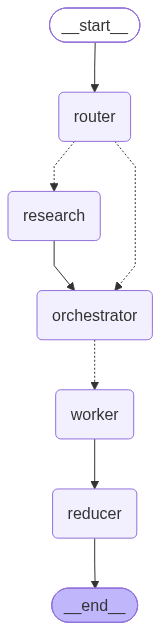

In [11]:
# -----------------------------
# 9) Build graph
# -----------------------------
g = StateGraph(State)
g.add_node("router", router_node)
g.add_node("research", research_node)
g.add_node("orchestrator", orchestrator_node)
g.add_node("worker", worker_node)
g.add_node("reducer", reducer_node)

g.add_edge(START, "router")
g.add_conditional_edges("router", route_next, {"research": "research", "orchestrator": "orchestrator"})
g.add_edge("research", "orchestrator")

g.add_conditional_edges("orchestrator", fanout, ["worker"])
g.add_edge("worker", "reducer")
g.add_edge("reducer", END)

app = g.compile()
app

In [12]:
# -----------------------------
# 10) Runner
# -----------------------------
def run(topic: str):
    # max_concurrency caps parallel worker calls: Ollama cloud rejects bursts with 429
    out = app.invoke(
        {
            "topic": topic,
            "mode": "",
            "needs_research": False,
            "queries": [],
            "evidence": [],
            "plan": None,
            "sections": [],
            "final": "",
        },
        config={"max_concurrency": 2},
    )

    return out

In [13]:
#run("Write a blog on Open Source LLMs in 2026")
run("State of Multimodal LLMs in 2026")

{'topic': 'State of Multimodal LLMs in 2026',
 'mode': 'open_book',
 'needs_research': True,
 'queries': ['latest multimodal large language models released in 2026',
  'benchmark performance of multimodal LLMs on vision-language tasks in 2026',
  'open-source multimodal LLM projects launched in 2026',
  'commercial pricing and API access details for multimodal LLM services in 2026',
  'key architectural innovations in multimodal LLMs reported in 2026',
  'evaluation datasets and leaderboards for multimodal LLMs in 2026',
  'industry adoption case studies of multimodal LLMs in 2026',
  'multimodal LLMs capabilities for video understanding as of 2026'],
 'evidence': [EvidenceItem(title='Ultimate Guide - The Best Multimodal AI Models in 2026 - SiliconFlow', url='https://www.siliconflow.com/articles/best-multimodal-ai-models', published_at=None, snippet='Qwen2.5-VL-32B-Instruct is a multimodal large language model released by the Qwen team, part of the Qwen2.5-VL series. This model is not 